# Summary of Imaging Analyses Results

__This notebook merges all the imaging analyses results together and output, adding necessary QC steps.__

1. Extract the hits for cell-count differences;

2. Extract the hits for protein abundance changes;

3. Extract the hits for mislocalization.

In [1]:
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from functools import reduce
import operator
from adjustText import adjust_text
import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *
from matplotlib.patches import Patch
import matplotlib.font_manager as fm

# Force TrueType font embedding (Type 42)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

font_path = "../../../../1_allele_collection/4_manuscript_figures/ARIAL.TTF"
fm.fontManager.addfont(font_path)

font_prop = fm.FontProperties(fname=font_path)
# Set font family to one of the accepted fonts
plt.rcParams.update({
    "font.family": font_prop.get_name(),
    "font.sans-serif": ["ARIAL"],
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

In [2]:
ALLELE_COLLECTION_INFO = "../../../../1_allele_collection/3_outputs"
IMG_PHENO_HIT_STRICT, IMG_PHENO_HIT, IMG_MISLOC_HIT = "Altered_99th_perc_both_batches_GFP", "Altered_95th_perc_both_batches_GFP", "Altered_95th_perc_both_batches_GFP_ADJ"

## 1. Loading Data

### 1.1 Metadata

In [3]:
clin_var_df = pl.read_csv(
    "../../../../1_allele_collection/3_outputs/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI_SpliceAI.tsv",
    separator="\t", infer_schema_length=100000
)

### 1.2 Imaging Analysis Results

In [4]:
cell_count_summary = pl.read_csv(
    f"../1_snakemake_pipeline/2025_varchamp_snakemake/3.downstream_analyses/outputs/1.cell_count_abundance_change/cell_count_diff_summary_oneperc.csv"
)
prot_abund_summary = pl.read_csv(
    f"../1_snakemake_pipeline/2025_varchamp_snakemake/3.downstream_analyses/outputs/1.cell_count_abundance_change/prot_abundance_diff_summary_oneperc.csv"
)
auroc_summary_df = pl.read_csv(
    f"../1_snakemake_pipeline/2025_varchamp_snakemake/3.downstream_analyses/outputs/2.classification_results/imaging_analyses_classification_summary_one_perc.csv"
)

#### 1.2.1 Merging duplicated cell-count and protein-abundance alleles

In [5]:
cc_prot_abun_df = cell_count_summary.join(
    prot_abund_summary,
    on=["Gene", "gene_variant", "Bio_Batch"],
    how="full",
    coalesce=True
).filter(
    ~(pl.col("gene_variant")=="ALK_Arg1275Gln") ## control alleles, need to be removed
)

## extract the alleles with only single appearance
variants_single = cc_prot_abun_df.group_by("gene_variant").len().filter(pl.col("len")==1)["gene_variant"]
cc_prot_abun_single = cc_prot_abun_df.filter(pl.col("gene_variant").is_in(variants_single))

## extract the alleles with replicates
variants_replicate = cc_prot_abun_df.group_by("gene_variant").len().filter(pl.col("len")>1).unique(subset="gene_variant")["gene_variant"]
cc_prot_abun_rep = cc_prot_abun_df.filter(
    pl.col("gene_variant").is_in(variants_replicate),
)
cc_prot_abun_rep.sort(by=["gene_variant","Bio_Batch"])
## manually filter the variants to have consistent batch with auroc scores
cc_prot_abun_rep_dedup = cc_prot_abun_rep.filter(
    ~((pl.col("gene_variant")=="BCL10_Leu8Leu") & (pl.col("Bio_Batch")!="B_13-14")),
    ~((pl.col("gene_variant")=="GSS_Arg125Cys") & (pl.col("Bio_Batch")!="B_13-14")),
    ~((pl.col("gene_variant")=="MVK_Ser329Asn") & (pl.col("Bio_Batch")!="B_11-12")),
    ~((pl.col("gene_variant")=="MVK_Pro288Leu") & (pl.col("Bio_Batch")!="B_11-12")),
    ~((pl.col("gene_variant")=="RAD51D_Arg165Gln") & (pl.col("Bio_Batch")!="B_13-14")),
)
cc_prot_abun_rep_dedup.sort(by=["gene_variant","Bio_Batch"])

cc_prot_abun_final_df = pl.concat([
    cc_prot_abun_single,
    cc_prot_abun_rep_dedup
])

cc_prot_abun_final_df.unique("gene_variant")

Gene,gene_variant,Bio_Batch,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_cc_t_pval_fdr_bh_adj,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,U2OS_prot_abun_t_pval_fdr_bh_adj
str,str,str,f64,f64,f64,f64,f64,f64
"""RHO""","""RHO_Asp190Gly""","""B_13-14""",-2.929431,0.022042,0.04865,-20.557453,1.6173e-7,0.000007
"""GCK""","""GCK_Met251Thr""","""B_7-8""",5.080192,0.014735,0.036645,6.530983,0.007295,0.013048
"""MLH1""","""MLH1_Leu653Pro""","""B_11-12""",2.11754,0.079734,0.135854,-4.323628,0.143833,0.18278
"""COMP""","""COMP_Cys348Arg""","""B_7-8""",-3.53283,0.038561,0.075155,1.53726,0.168114,0.209571
"""SHOC2""","""SHOC2_Met173Val""","""B_13-14""",-0.392641,0.706267,0.767332,5.776885,0.000679,0.00174
…,…,…,…,…,…,…,…,…
"""F9""","""F9_Ser220Thr""","""B_13-14""",-1.581368,0.157807,0.233472,-1.008061,0.346993,0.399456
"""PLP1""","""PLP1_Pro181Ser""","""B_7-8""",0.808239,0.449803,0.537961,0.92146,0.392354,0.445802
"""BRCA1""","""BRCA1_Val275Ile""","""B_13-14""",-0.421954,0.685715,0.750124,3.575784,0.009027,0.015686


In [6]:
imaging_summary = cc_prot_abun_final_df.join(
    ## ONLY merge alleles with AUROC called, discard all the variants with ONLY CC and Abundance
    auroc_summary_df,
    left_on=["Gene", "gene_variant"],
    right_on=["symbol", "gene_variant"],
    how="full",
    coalesce=True
)
imaging_summary.unique("gene_variant")

Gene,gene_variant,Bio_Batch,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_cc_t_pval_fdr_bh_adj,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_pval,U2OS_prot_abun_t_pval_fdr_bh_adj,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,AUROC_BioRep2_GFP_ADJ
str,str,str,f64,f64,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""F9""","""F9_Ile136Thr""","""B_13-14""",1.859606,0.105272,0.170688,-4.410902,0.003115,0.006227,"""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,false,false,0.657918,0.678402,0.648341,0.685916,0.754616,0.712557,0.682111,0.743302,0.681577,0.601158,0.664039,0.655838,0.743003,0.765929,0.690255,0.695525,0.692764,0.659999
"""GFAP""","""GFAP_Asn77Ser""","""B_15-16""",0.602116,0.566081,0.644348,11.461787,0.000009,0.00007,"""2025_03_Batch_15-16""",true,true,false,false,false,false,true,false,false,false,false,false,0.979233,0.968505,0.589523,0.814242,0.868859,0.71119,0.612648,0.869974,0.734454,0.582658,0.960269,0.97184,0.809732,0.867744,0.89403,0.596389,0.97674,0.986627
"""TPM1""","""TPM1_Glu54Lys""","""B_15-16""",1.422163,0.20571,0.286395,0.004715,1.0,1.0,"""2025_03_Batch_15-16""",false,false,false,false,false,false,false,false,false,false,false,false,0.693807,0.707535,0.708342,0.762543,0.757603,0.742366,0.625121,0.628094,0.645447,0.618131,0.614315,0.620234,0.859611,0.887112,0.879639,0.798552,0.800755,0.767379
"""BRAF""","""BRAF_Gly464Val""","""B_13-14""",-4.383116,0.003222,0.011293,-0.542517,0.604296,0.652285,"""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,false,false,0.769576,0.833652,0.601362,0.769516,0.793183,0.733807,0.752996,0.780593,0.847488,0.600395,0.859511,0.766843,0.714618,0.805773,0.691544,0.602328,0.807793,0.772308
"""BRCA1""","""BRCA1_His239Arg""","""B_13-14""",1.417428,0.199296,0.280306,3.364407,0.012012,0.020056,"""2025_01_Batch_13-14""",false,false,true,true,true,true,false,false,true,true,false,true,0.929404,0.93071,0.930888,0.96099,0.922479,0.977156,0.983467,0.930533,0.954667,0.945236,0.921688,0.932445,0.970845,0.914426,0.967312,0.91654,0.939731,0.926363
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""F9""","""F9_Gly442Arg""","""B_13-14""",1.740571,0.125305,0.196102,-1.800024,0.11488,0.149614,"""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,false,false,0.597151,0.581086,0.609215,0.627176,0.619239,0.64895,0.732307,0.757306,0.765709,0.643283,0.636692,0.676478,0.565593,0.481172,0.488643,0.575146,0.525479,0.517824
"""UBQLN2""","""UBQLN2_Pro497Ser""","""B_7-8""",1.54779,0.165599,0.241999,-2.101618,0.073695,0.100022,"""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,false,false,0.693501,0.693222,0.685988,0.715521,0.614506,0.723308,0.735097,0.618555,0.823868,0.695399,0.675548,0.694383,0.711519,0.610457,0.607173,0.676577,0.710897,0.69262
"""KRAS""","""KRAS_Pro34Arg""","""B_13-14""",-1.876584,0.10268,0.16758,8.780959,0.00005,0.000242,"""2025_01_Batch_13-14""",false,false,false,false,false,false,false,false,false,false,false,false,0.856767,0.878771,0.550921,0.763906,0.775671,0.703174,0.659831,0.737687,0.653443,0.554526,0.855457,0.818794,0.746516,0.813656,0

### 1.3 Merge imaging with Allele QC and ClinVar info

In [7]:
## oneperc data
imaging_summary_oneperc_clinvar = imaging_summary.filter(
    pl.col("Metadata_Bio_Batch") != "2025_01_Batch_13-14"
).join(
    clin_var_df,
    left_on="gene_variant",
    right_on="gene_variant",
    how="inner"
).with_columns(
    pl.when(pl.col("inheritance_pattern").is_null())
    .then(pl.lit("unknown"))
    .otherwise(pl.col("inheritance_pattern"))
    .alias("inheritance_pattern")
)
## needs to verify by sequence for mislocalization assay
mutant_mask_all = (pl.col("mislocalization_seq_final")=="Y")

# ## ============ Deprecated, kept for reference ============
# # seq_conf_cols = [
# #     "entry_sequence_confirmation_class",
# #     "mislocalization_sequence_confirmation_class",
# # ]
# # imaging_summary_oneperc_clinvar = imaging_summary_oneperc_clinvar.with_columns([
# #     pl.col(col).cast(pl.Float64, strict=False) for col in seq_conf_cols
# # ])
# # ## Define masks for variant allele filtering
# # # At least one entry sequence vector is good
# # any_expression_good = (
# #     pl.col("entry_sequence_confirmation_class").is_in([1, 2])
# # )
# # entry_good = pl.col("mislocalization_sequence_confirmation_class").is_in([1, 2])
# # entry_null_like = pl.col("mislocalization_sequence_confirmation_class").is_in([7, 99]) | pl.col("mislocalization_sequence_confirmation_class").is_null()
# # mutant_mask_all = entry_good | (entry_null_like & any_expression_good)
# ## ========================================================

## Combine logic
imaging_summary_oneperc_clinvar = imaging_summary_oneperc_clinvar.filter(
    mutant_mask_all
).unique("gene_variant")

## add CAVA gene
imaging_summary_cava_clinvar = imaging_summary.filter(
    pl.col("Metadata_Bio_Batch") == "2025_01_Batch_13-14"
).join(
    ## ONLY keep the VarChAMP collection alleles (two F9 variants are dropped)
    clin_var_df,
    left_on="gene_variant",
    right_on="gene_variant",
    how="inner" ## ONLY keep the VarChAMP collection
).with_columns(
    pl.when(pl.col("inheritance_pattern").is_null())
    .then(pl.lit("unknown"))
    .otherwise(pl.col("inheritance_pattern"))
    .alias("inheritance_pattern"),
).unique("gene_variant")

imaging_summary_clinvar = pl.concat(
    [imaging_summary_oneperc_clinvar, imaging_summary_cava_clinvar]
).with_columns(
    ## some alleles didn't exist in the allele collection
    pl.col("clinvar_clnsig_clean_pp_strict").fill_null("Others").alias("clinvar_clnsig_clean_pp_strict"),
    pl.col("clinvar_clnsig_clean").fill_null("Others").alias("clinvar_clnsig_clean")
).with_columns(
    pl.col("clinvar_clnsig_clean_pp_strict").cast(pl.Enum(clinvar_order_dict["original"])).alias("clinvar_clnsig_clean_pp_strict")
).sort("clinvar_clnsig_clean_pp_strict")

imaging_summary_clinvar = imaging_summary_clinvar.with_columns(
    pl.col("AUROC_Mean_GFP").alias("img_pheno_score"),
    pl.col("AUROC_Mean_GFP_ADJ").alias("img_misloc_score"),
    (pl.col(IMG_PHENO_HIT)==1).alias("img_pheno_hit"),
    (pl.col(IMG_MISLOC_HIT)==1).alias("img_misloc_hit"),
    (pl.col(IMG_PHENO_HIT_STRICT)==1).alias("img_pheno_hit_strict"),
    pl.col("clinvar_clnsig_clean_pp_strict")
        .cast(pl.Enum(clinvar_order_dict["original"])),
    pl.col("clinvar_clnsig_clean")
        .cast(pl.Enum([c for c in clinvar_order_dict["original"] if "Likely" not in c]))
)

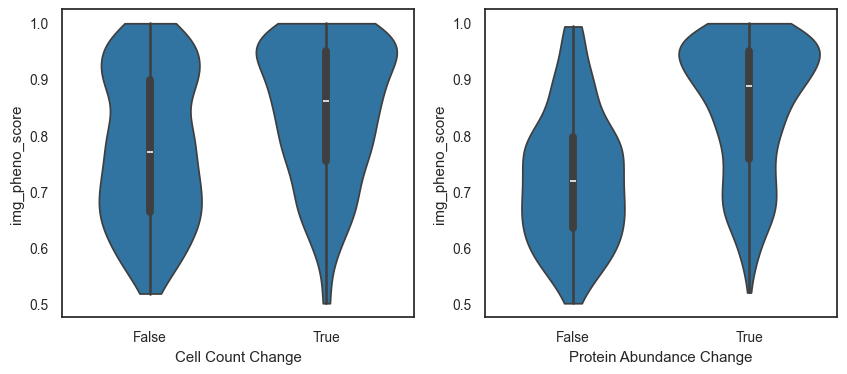

In [8]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
sns.violinplot(
    data=imaging_summary_clinvar.filter(
        pl.col("U2OS_cc_t_pval_fdr_bh_adj").is_not_null()
    ).with_columns(
        (pl.col("U2OS_cc_t_pval_fdr_bh_adj")<0.05).alias("Cell Count Change"),
    ).to_pandas(),
    x="Cell Count Change",
    y="img_pheno_score",
    cut=0,
    ax=axes[0]
)
sns.violinplot(
    data=imaging_summary_clinvar.filter(
        pl.col("U2OS_prot_abun_t_pval_fdr_bh_adj").is_not_null()
    ).with_columns(
        (pl.col("U2OS_prot_abun_t_pval_fdr_bh_adj")<0.05).alias("Protein Abundance Change")
    ).to_pandas(),
    x="Protein Abundance Change",
    y="img_pheno_score",
    cut=0,
    ax=axes[1]
)
plt.show()

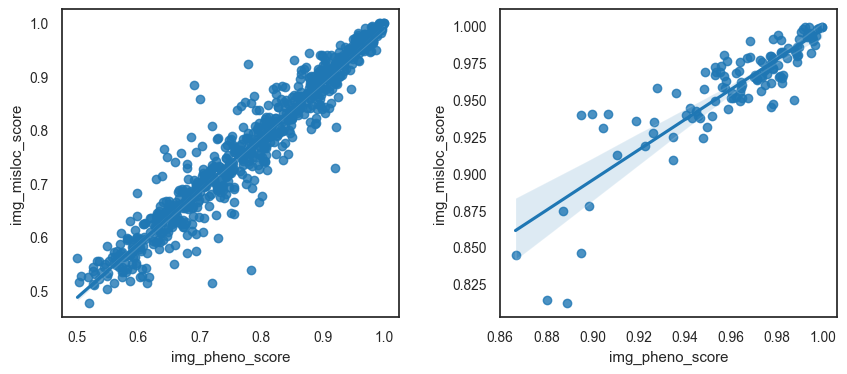

In [9]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
sns.regplot(
    data=imaging_summary_clinvar.to_pandas(),
    x="img_pheno_score",
    y="img_misloc_score",
    ax=axes[0]
)
sns.regplot(
    data=imaging_summary_clinvar.filter(
        (pl.col("img_pheno_hit")) | (pl.col("img_misloc_hit"))
    ).to_pandas(),
    x="img_pheno_score",
    y="img_misloc_score",
    ax=axes[1]
)
plt.subplots_adjust(wspace=.3)
plt.show()

In [11]:
print(f"All imaged alleles: {imaging_summary_clinvar.shape[0]}")

imaging_phenotype_clinvar = imaging_summary_clinvar.filter(
    (pl.col("AUROC_Mean_GFP").is_not_null())
)
print(f"Imaging phenotype reported alleles: {imaging_phenotype_clinvar.shape[0]}")

All imaged alleles: 839
Imaging phenotype reported alleles: 806


In [ ]:
# imaging_summary_clinvar.write_csv("../../3_outputs/0_imaging_analyses_summary_clinvar.tsv", separator="\t")
# imaging_phenotype_clinvar.write_csv("../../3_outputs/0_imaging_phenotype_summary_clinvar.tsv", separator="\t")

## 2. Data Summary

In [12]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/0_imaging_phenotype_summary_clinvar.tsv", separator="\t", infer_schema_length=100000).with_columns(
    pl.col("clinvar_clnsig_clean_pp_strict")
        .cast(pl.Enum(clinvar_order_dict["original"])),
    pl.col("clinvar_clnsig_clean")
        .cast(pl.Enum([c for c in clinvar_order_dict["original"] if "Likely" not in c]))
)
imaging_summary_clinvar#.unique("Gene")

# with pl.Config(set_tbl_rows=20):
#     display(
#         imaging_summary_clinvar.filter(
#             pl.col("Metadata_Bio_Batch")=="2024_12_Batch_11-12"
#         ).filter(pl.col("Gene")=="MVK")
#     )
#     display(
#         imaging_summary_clinvar.filter(pl.col("Gene")=="MVK")
#     )

## Cell count change
print(
    "Cell count change alleles:",
    imaging_summary_clinvar.filter(
        (pl.col("U2OS_cc_t_stat").is_not_null()) & (pl.col("U2OS_cc_t_pval") < 0.05/943)
    ).shape[0]
)


## Protein abundance change
print(
    "Protein abundance change alleles:",
    imaging_summary_clinvar.filter(
        (pl.col("U2OS_prot_abun_t_stat").is_not_null()) & (pl.col("U2OS_prot_abun_t_pval") < 0.05/943)
    ).shape[0]
)


## Mislocalization change
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col("Altered_95th_perc_both_batches_GFP")
)
imaging_summary_clinvar_misloc_hits = imaging_summary_clinvar.filter(
    pl.col("Altered_95th_perc_both_batches_GFP_ADJ")
)
print("Imaging Phenotype change alleles:", imaging_summary_clinvar_hits.shape[0])
print("Mislocalization change alleles:", imaging_summary_clinvar_misloc_hits.shape[0])
imaging_summary_clinvar.filter(
    (pl.col("Altered_95th_perc_both_batches_GFP")) | (pl.col("Altered_95th_perc_both_batches_GFP_ADJ"))
).select(
    "gene_variant", "Altered_95th_perc_both_batches_GFP", "Altered_95th_perc_both_batches_GFP_ADJ", "AUROC_Mean_GFP", "AUROC_Mean_GFP_ADJ", "clinvar_clnsig_clean"
)

df = imaging_summary_clinvar.to_pandas() ## drop_nulls("clinvar_clnsig_clean").

Cell count change alleles: 15
Protein abundance change alleles: 70
Imaging Phenotype change alleles: 128
Mislocalization change alleles: 97


### 2.1 ClinVar and Inheritance Pattern Summary

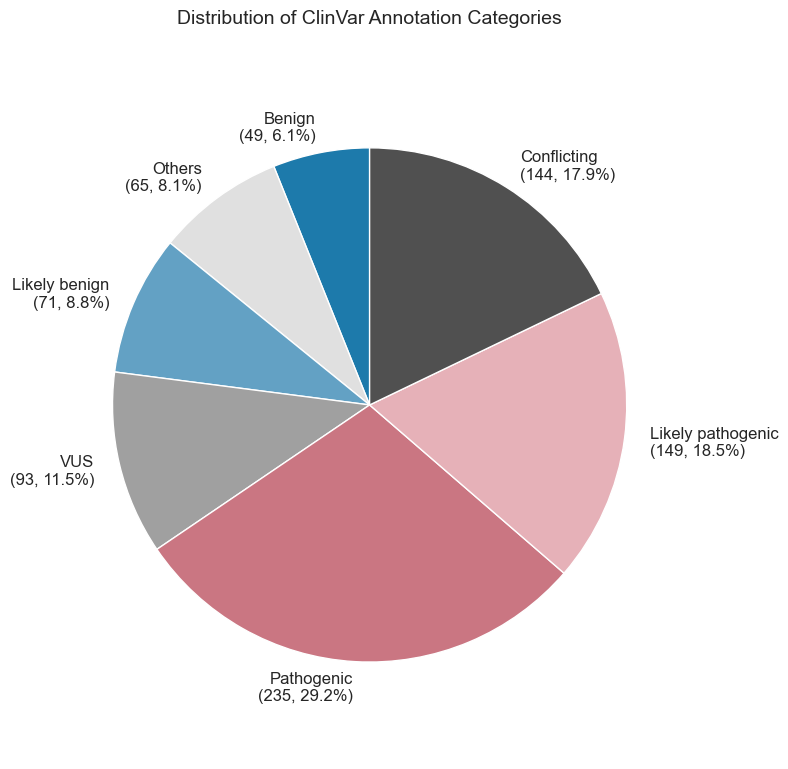

ClinVar Annotation Distribution:
Benign: 49 variants (6.1%)
Others: 65 variants (8.1%)
Likely benign: 71 variants (8.8%)
VUS: 93 variants (11.5%)
Pathogenic: 235 variants (29.2%)
Likely pathogenic: 149 variants (18.5%)
Conflicting: 144 variants (17.9%)

Total variants: 806


In [45]:
# Create pie chart for ClinVar annotation categories
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
# Get the category counts from the merged data
summary_clin_var_counts = imaging_summary_clinvar.group_by("clinvar_clnsig_clean_pp_strict").agg(pl.len()).to_pandas()
summary_clin_var_counts['clinvar_clnsig_clean_pp_strict'] = pd.Categorical(
    summary_clin_var_counts['clinvar_clnsig_clean_pp_strict'], 
    categories=clinvar_order_dict["original"], 
    ordered=True
)
summary_clin_var_counts

# Convert to pandas for easier plotting
pie_data = summary_clin_var_counts#.sort_values('clinvar_clnsig_clean_pp_strict')
# pie_data = pie_data.dropna()  # Remove any null values

# Calculate percentages
total_count = pie_data["len"].sum()
pie_data["percentage"] = (pie_data["len"] / total_count * 100).round(1)

# Create labels with counts and percentages
labels = [f"{cat}\n({count}, {pct}%)" for cat, count, pct in zip(pie_data["clinvar_clnsig_clean_pp_strict"], 
                                                                 pie_data["len"], 
                                                                 pie_data["percentage"])
]
colors = [palette_dict["clinvar_clnsig_clean_pp_strict"][cat] for cat in pie_data["clinvar_clnsig_clean_pp_strict"]]
# Create pie chart
wedges, texts, autotexts = ax.pie(pie_data["len"], 
                                  labels=labels, 
                                  colors=colors,
                                  autopct="",  # We're including percentages in labels
                                  startangle=90,
                                  textprops={'fontsize': 12})

ax.set_title("Distribution of ClinVar Annotation Categories", fontsize=14, fontweight='bold', pad=20)
# Equal aspect ratio ensures that pie is drawn as a circle
ax.axis('equal')

# # Add a legend
# ax.legend(wedges, [f"{cat} (n={count})" for cat, count in zip(pie_data["clinvar_clnsig_clean"], pie_data["len"])],
#           title="Categories",
#           loc="center left",
#           bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.show()

# Print summary statistics
print("ClinVar Annotation Distribution:")
print("=" * 40)
for _, row in pie_data.iterrows():
    print(f"{row['clinvar_clnsig_clean_pp_strict']}: {row['len']} variants ({row['percentage']}%)")
print(f"\nTotal variants: {total_count}")

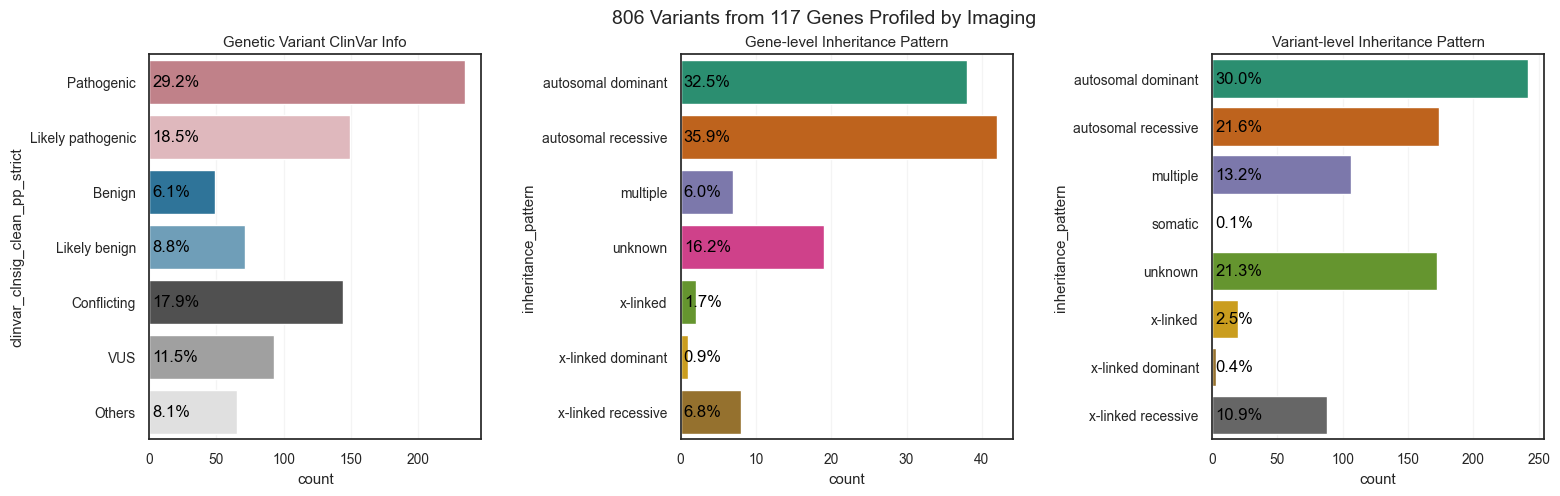

In [46]:
fig, axes = plt.subplots(1,3,figsize=(18,5))
plot_cat_count_perc(
    imaging_summary_clinvar,
    "clinvar_clnsig_clean_pp_strict",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
axes[0].set_title("Genetic Variant ClinVar Info")

plot_cat_count_perc(
    imaging_summary_clinvar.unique("symbol"),
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)
axes[1].set_title("Gene-level Inheritance Pattern")

plot_cat_count_perc(
    imaging_summary_clinvar,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[2],
)
axes[2].set_title("Variant-level Inheritance Pattern")

plt.suptitle(f"{imaging_summary_clinvar.unique('gene_variant').shape[0]} Variants from {imaging_summary_clinvar.unique('symbol').shape[0]} Genes Profiled by Imaging", y=.97, fontsize=14)
plt.subplots_adjust(wspace=.6)
plt.show()

### 2.2 Gene-level Summary

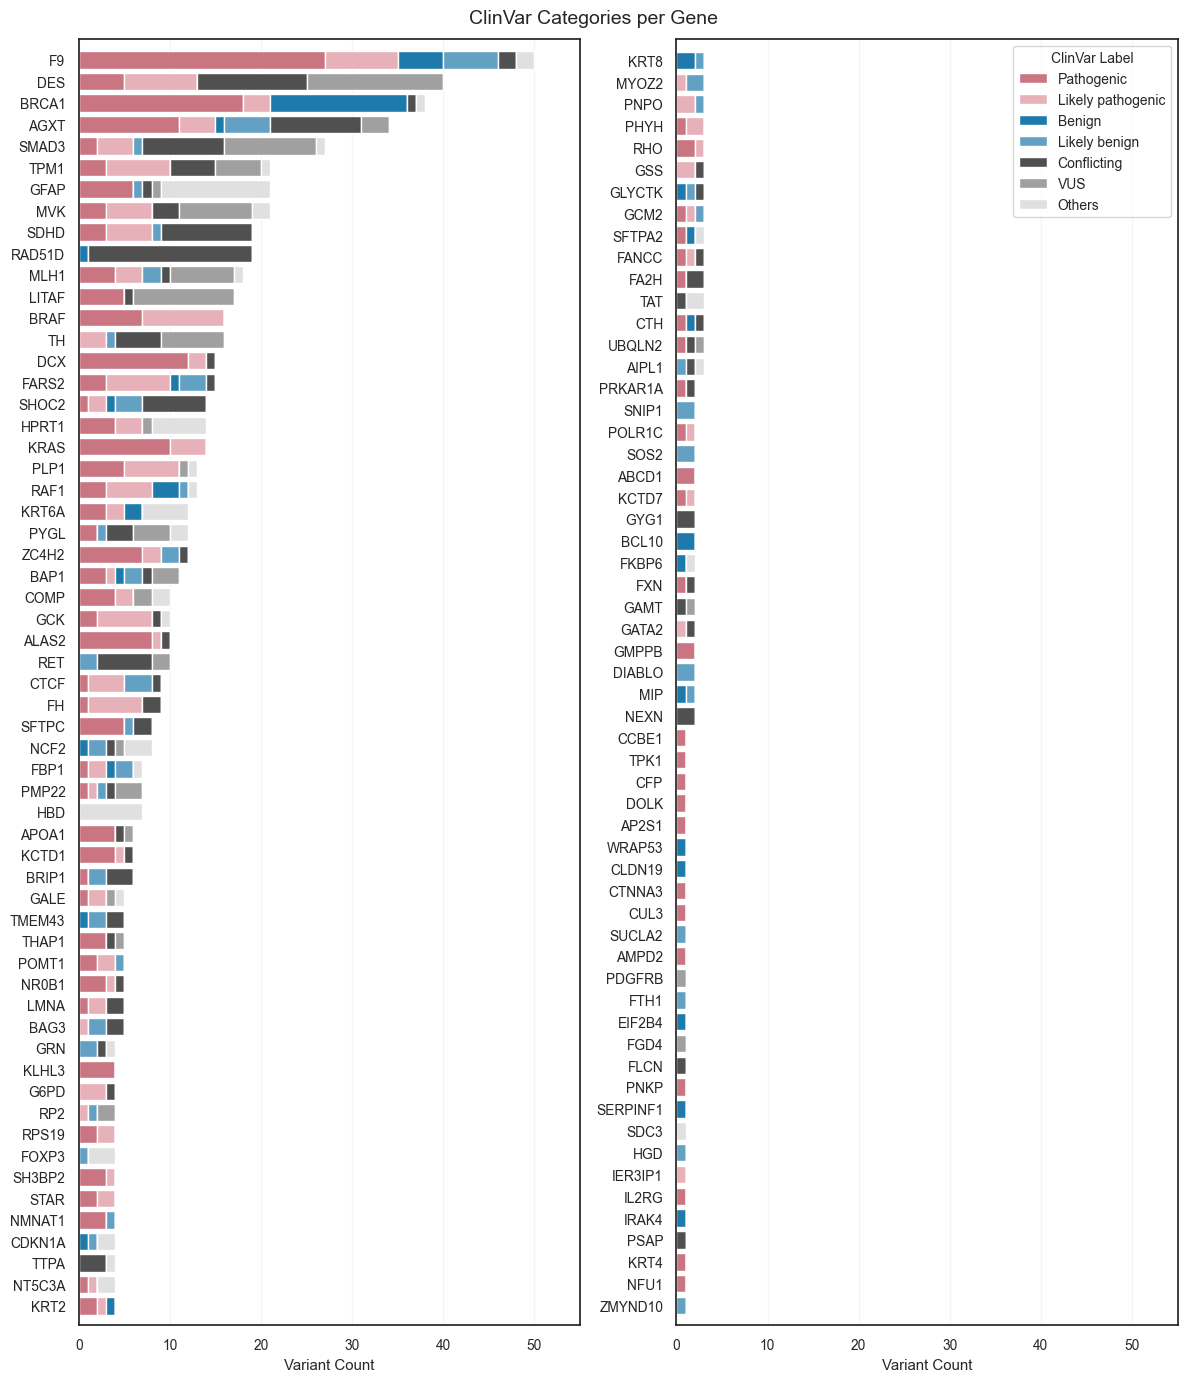

In [47]:
top_num = int(np.ceil(imaging_summary_clinvar.unique("symbol").shape[0] / 2))
counts = (
    df.groupby(["symbol", "clinvar_clnsig_clean_pp_strict"])
    .size()
    .reset_index(name="count")
)
# 3. Pivot
pivot = counts.pivot(index="symbol", columns="clinvar_clnsig_clean_pp_strict", values="count").fillna(0)

# Add total count column and sort by it (descending)
pivot["total_count"] = pivot.sum(axis=1)
pivot_top = pivot.sort_values("total_count", ascending=False).head(top_num)
pivot_top = pivot_top.drop(columns=["total_count"])

# 4. Ensure category order
for cat in clinvar_order_dict["original"]:
    if cat not in pivot_top.columns:
        pivot_top[cat] = 0
pivot_top = pivot_top[clinvar_order_dict["original"]]

# 5. Plotting
fig, axes = plt.subplots(1,2, figsize=(12, 14))
# Get Set2 colors
bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean_pp_strict"].items():
    axes[0].barh(pivot_top.index, pivot_top[cat], 
            left=bottom, label=cat, color=color)
    bottom = pivot_top[cat] if bottom is None else bottom + pivot_top[cat]
    
# Axis formatting
axes[0].set_xlabel("Variant Count")
axes[0].set_xlim(None, 55)
axes[0].set_ylim(-1, pivot_top.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[0].set_title(f"ClinVar Categories per Gene (Top {top_num} with Most Variants)", fontsize=14)
axes[0].invert_yaxis()
axes[0].grid(alpha=.2, axis="x")

# ax.legend(title="ClinVar Label", fontsize=9, title_fontsize=10, loc="lower right")
# plt.tight_layout()
# plt.show()

pivot_bot = pivot.sort_values("total_count", ascending=False).iloc[top_num:,].copy()
pivot_bot = pivot_bot.drop(columns=["total_count"])

# 4. Ensure category order
for cat in clinvar_order_dict["original"]:
    if cat not in pivot_bot.columns:
        pivot_bot[cat] = 0
pivot_bot = pivot_bot[clinvar_order_dict["original"]]

bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean_pp_strict"].items():
    axes[1].barh(pivot_bot.index, pivot_bot[cat], left=bottom, label=cat, color=color)
    bottom = pivot_bot[cat] if bottom is None else bottom + pivot_bot[cat]
    
# Axis formatting
axes[1].set_xlabel("Variant Count")
axes[1].set_xlim(None, 55)
axes[1].set_ylim(-1, pivot_bot.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[1].set_title(f"ClinVar Categories per Gene ({top_num} After)", fontsize=14)
axes[1].invert_yaxis()
axes[1].legend(title="ClinVar Label", fontsize=10, title_fontsize=10, loc="upper right")
axes[1].grid(alpha=.2, axis="x")
plt.suptitle(f"ClinVar Categories per Gene", fontsize=14, y=.985)
plt.tight_layout()
plt.show()

<ipython-input-48-2b58b12dd427>:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')


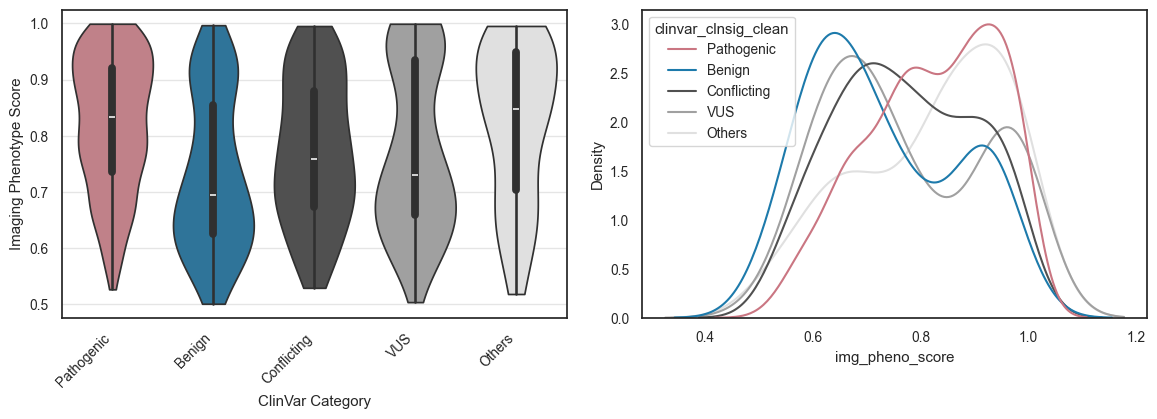

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# sns.boxenplot(
#     data=scores.to_pandas(),
#     x="clinvar_clnsig_clean", 
#     y="dualipa_abun_score",
#     hue="clinvar_clnsig_clean", 
#     palette=palette_dict["clinvar_clnsig_clean"],
#     order=hue_order,
#     ax=axes[0]
# )
sns.violinplot(
    data=df,
    x="clinvar_clnsig_clean", 
    y="img_pheno_score", ## AUROC_Mean_GFP
    hue="clinvar_clnsig_clean", 
    palette=palette_dict["clinvar_clnsig_clean"],
    hue_order=[cat for cat in clinvar_order_dict["original"] if "Likely" not in cat],
    cut=0,
    ax=axes[0]
)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_xlabel("ClinVar Category") ##, rotation=45, ha='right'
axes[0].set_ylabel("Imaging Phenotype Score") ##, rotation=45, ha='right'
axes[0].grid(alpha=0.5, axis="y")

sns.kdeplot(
    data=df,
    x="img_pheno_score",
    hue="clinvar_clnsig_clean",
    hue_order=[cat for cat in clinvar_order_dict["original"] if "Likely" not in cat],
    ax=axes[1],
    palette=palette_dict["clinvar_clnsig_clean"],
    common_norm=False
)
plt.subplots_adjust(wspace=0.15)
plt.show()

In [49]:
# plot_gene_level_summary(
#     imaging_summary_clinvar.with_columns(
#         (
#             (pl.col("Altered_95th_perc_both_batches_GFP"))
#         ).alias("hit_by_an_assay")
#     ).filter(
#         pl.col("Gene").is_in(imaging_summary_clinvar_hits["Gene"].unique())
#     ),
#     assay="hit_by_an_assay", 
#     cat="clinvar_clnsig_clean_pp_strict", 
#     palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
#     plot=True
# )

# plot_gene_level_summary(
#     imaging_summary_clinvar.with_columns(
#         (
#             (pl.col("Altered_95th_perc_both_batches_GFP"))
#         ).alias("hit_by_an_assay")
#     ).filter(
#         ~pl.col("Gene").is_in(imaging_summary_clinvar_hits["Gene"].unique())
#     ),
#     assay="hit_by_an_assay", 
#     cat="clinvar_clnsig_clean_pp_strict", 
#     palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
#     plot=True
# )

## 3. Analyses with different categories

### 3.1 ClinVar

In [50]:
# fig, axes = plt.subplots(1,2,figsize=(14, 4.5))
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="clinvar_clnsig_clean",
#     palette=palette_dict["clinvar_clnsig_clean"],
#     common_norm=False,
#     hue_order=sorted(palette_dict["clinvar_clnsig_clean"].keys()),
#     ax=axes[0]
# )
# sns.boxenplot(
#     data=imaging_summary_clinvar.filter(
#         pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS"])
#     ).to_pandas(),
#     y="AUROC_Mean_GFP",
#     x="clinvar_clnsig_clean",
#     hue="clinvar_clnsig_clean",
#     palette=palette_dict["clinvar_clnsig_clean"],
#     order=imaging_summary_clinvar.filter(
#         pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS"])
#     ).group_by(
#         "clinvar_clnsig_clean"
#     ).agg(
#         pl.median("AUROC_Mean_GFP").alias("clinvar_median")
#     ).sort("clinvar_median", descending=True)["clinvar_clnsig_clean"],
#     # hue_order=sorted(palette_dict["clinvar_clnsig_clean"].keys()),
#     ax=axes[1]
# )
# axes[1].grid(alpha=.2, axis="y")
# # xtick_inher = axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=60, ha="right")

# fig, axes = plt.subplots(1,2,figsize=(14, 4.5))
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="inheritance_pattern",
#     palette="Set2",
#     common_norm=False,
#     ax=axes[0],
#     warn_singular=False
# )
# axes[1].grid(alpha=.2)
# sns.boxenplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     y="AUROC_Mean_GFP",
#     x="inheritance_pattern",
#     # hue="inheritance_pattern",
#     # palette="Dark2",
#     order=imaging_summary_clinvar.group_by(
#         "inheritance_pattern"
#     ).agg(
#         pl.median("AUROC_Mean_GFP").alias("inher_median")
#     ).sort("inher_median", descending=True)["inheritance_pattern"],
#     # hue_order=sorted(clinvar_palette_old.keys()),
#     ax=axes[1],
# )

# xtick_inher = axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=60, ha="right")
# axes[1].grid(alpha=.2, axis="y")
# plt.subplots_adjust(wspace=.15)
# plt.show()

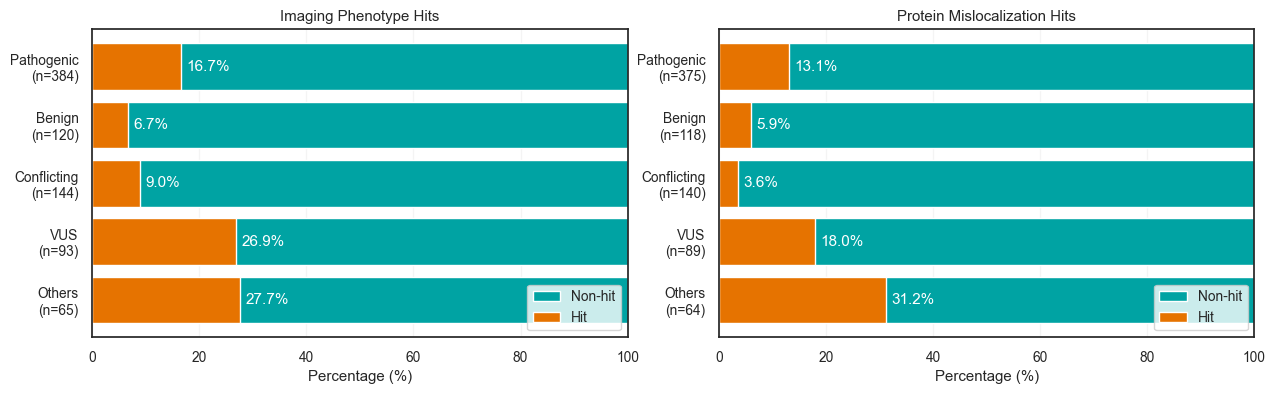

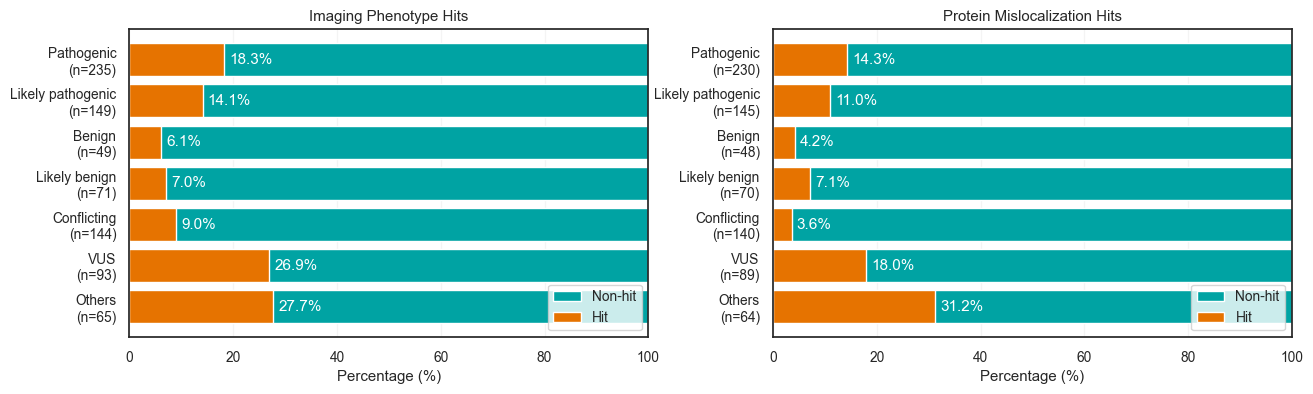

In [13]:
# img_metric_df = imaging_summary_clinvar.with_columns(
#     (pl.col(GFP_MISLOCAL_FEAT_STRICT)==1).alias("img_prot_pheno_hits_5perc_strict"),
#     (pl.col(GFP_MISLOCAL_FEAT_LENIENT)==1).alias("img_prot_pheno_hits_5perc"),
#     (pl.col("Altered_95th_perc_both_batches_GFP_ADJ")==1).alias("img_prot_misloc_hits_5perc"),
#     pl.col("clinvar_clnsig_clean_pp_strict")
#         .cast(pl.Enum(clinvar_order_dict["original"])),
#     pl.col("clinvar_clnsig_clean")
#         .cast(pl.Enum([c for c in clinvar_order_dict["original"] if "Likely" not in c]))
# ).sort("clinvar_clnsig_clean_pp_strict")

fig, axes = plt.subplots(1,2,figsize=(15,4),sharey=False)
# plot_assay_hit_by_category_perc
plot_assay_hit_by_category_perc(imaging_summary_clinvar, "img_pheno_hit", "clinvar_clnsig_clean", f"Imaging Phenotype Hits", ax=axes[0])
plot_assay_hit_by_category_perc(imaging_summary_clinvar.filter(pl.col("img_misloc_hit").is_not_null()), "img_misloc_hit", "clinvar_clnsig_clean", f"Protein Mislocalization Hits", ax=axes[1])
# plot_assay_hit_by_category_perc(img_metric_df, "img_prot_pheno_hits_5perc_strict", "clinvar_clnsig_clean", f"Protein Mislocalization Hits Strict", ax=axes[1])
plt.subplots_adjust(wspace=.17)
plt.show()

fig, axes = plt.subplots(1,2,figsize=(15,4),sharey=False)
# plot_assay_hit_by_category_perc
plot_assay_hit_by_category_perc(imaging_summary_clinvar, "img_pheno_hit", "clinvar_clnsig_clean_pp_strict", f"Imaging Phenotype Hits", ax=axes[0])
plot_assay_hit_by_category_perc(imaging_summary_clinvar.filter(pl.col("img_misloc_hit").is_not_null()), "img_misloc_hit", "clinvar_clnsig_clean_pp_strict", f"Protein Mislocalization Hits", ax=axes[1])
# plot_assay_hit_by_category_perc(img_metric_df, "img_prot_pheno_hits_5perc_strict", "clinvar_clnsig_clean_pp_strict", f"Protein Mislocalization Hits Strict", ax=axes[1])
plt.subplots_adjust(wspace=.24)
plt.show()

<ipython-input-52-bbd2bbcfb327>:15: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')


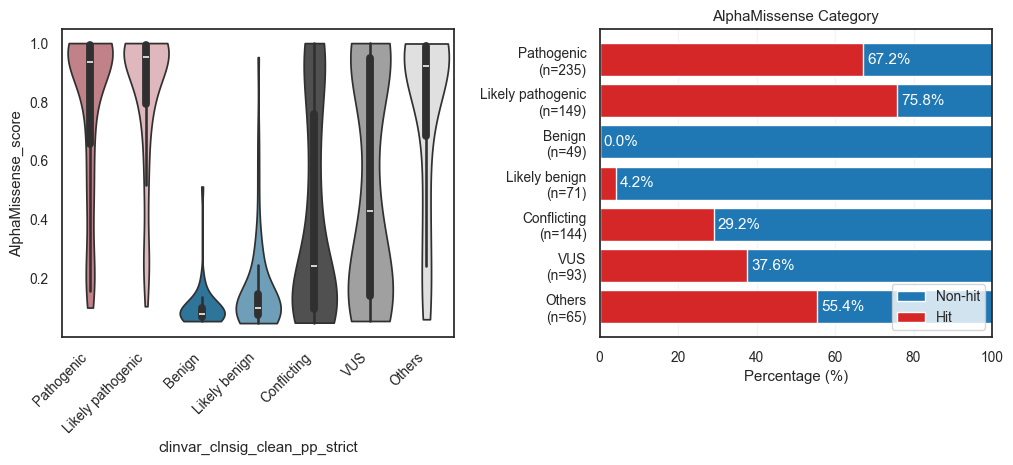

In [52]:
df["AlphaMissense_score"] = df["AlphaMissense_score"].replace(".",np.nan).astype(float)
df["AlphaMissense_pred_call"] = df["AlphaMissense_pred"].astype(str).apply(lambda x : True if "P" in x else False)

fig, axes = plt.subplots(1,2,figsize=(12,4),sharey=False)
sns.violinplot(
    data=df,
    x="clinvar_clnsig_clean_pp_strict", 
    y="AlphaMissense_score", ## AUROC_Mean_GFP
    hue="clinvar_clnsig_clean_pp_strict", 
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
    order=clinvar_order_dict["original"],
    cut=0,
    ax=axes[0]
)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

plot_assay_hit_by_category_perc(
    pl.DataFrame(df).with_columns(
        pl.col("clinvar_clnsig_clean_pp_strict")
            .cast(pl.Enum(clinvar_order_dict["original"]))
    ).sort("clinvar_clnsig_clean_pp_strict"), 
    "AlphaMissense_pred_call", 
    "clinvar_clnsig_clean_pp_strict", 
    f"AlphaMissense Category", 
    ax=axes[1]
)
plt.subplots_adjust(wspace=0.37)
plt.show()

#### 3.1.1 AUROC's predictive power for pathogenicity

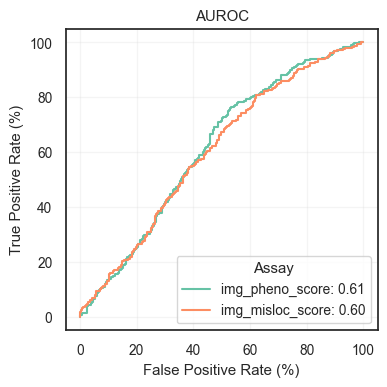

In [53]:
ap_results_dict = plot_auroc_curves(imaging_summary_clinvar, 
                                    label="clinvar_clnsig_clean",
                                    pos_labels=["Pathogenic"], 
                                    methods=["img_pheno_score", "img_misloc_score"])

## 4. Protein Structural Analyses

### 4.1 pLDDT and RSA

In [54]:
imaging_summary_clinvar.unique("RSA_Category")["RSA_Category"]

RSA_Category
str
"""<10"""
"""$\geqslant$90"""
"""10-90"""
"""NaN"""


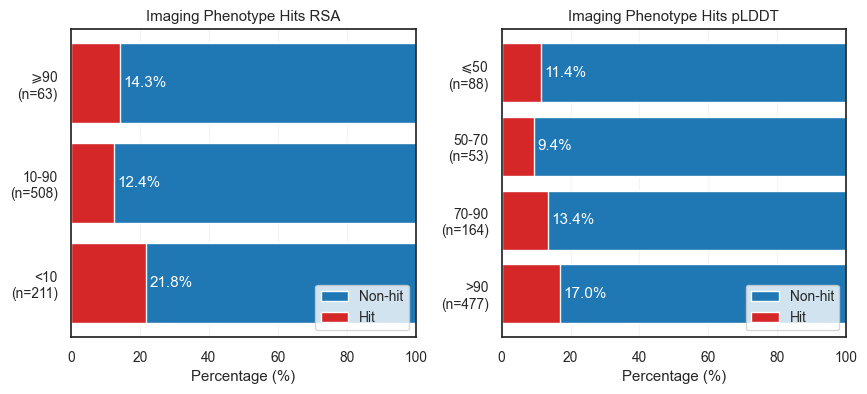

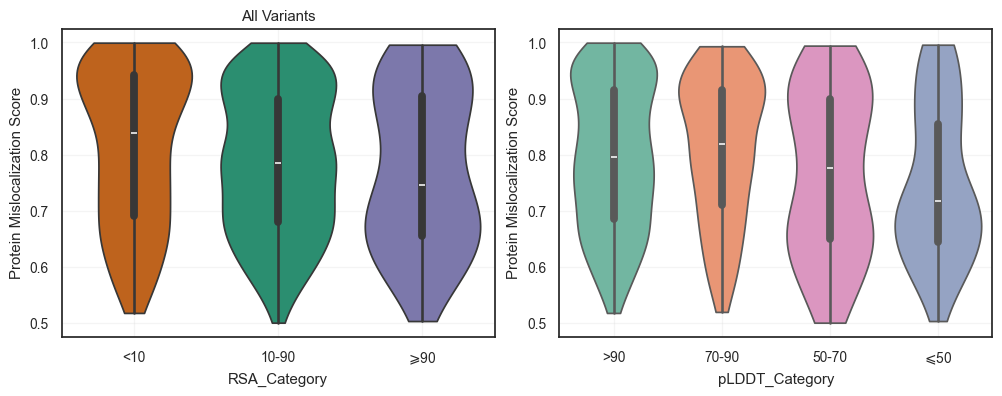

In [55]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
plot_assay_hit_by_category_perc(imaging_summary_clinvar.drop_nulls("RSA_Category").filter(pl.col("RSA_Category")!="NaN"), 
"img_pheno_hit", "RSA_Category", f"Imaging Phenotype Hits RSA", ax=axes[0])
plot_assay_hit_by_category_perc(imaging_summary_clinvar.drop_nulls("pLDDT_Category").filter(pl.col("RSA_Category")!="NaN"), 
"img_pheno_hit", "pLDDT_Category", f"Imaging Phenotype Hits pLDDT", ax=axes[1])
plt.subplots_adjust(wspace=.25)
plt.show()

fig, axes = plt.subplots(1,2,figsize=(12, 4))
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="RSA_Category",
#     palette="Set2",
#     common_norm=False,
#     # hue_order=sorted(clinvar_palette_old.keys()),
#     ax=axes[0]
# )
# sns.kdeplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     hue="pLDDT_Category",
#     palette="Set2",
#     common_norm=False,
#     # hue_order=sorted(clinvar_palette_old.keys()),
#     ax=axes[1]
# )
plot_data = imaging_summary_clinvar.filter(
    pl.col("RSA_Category")!="NaN",
    pl.col("RSA_Category").is_not_null()
).to_pandas()
groups_order = ['<10', '10-90', '$\geqslant$90']
sns.violinplot(
    data=plot_data,
    y="AUROC_Mean_GFP",
    x="RSA_Category",
    hue="RSA_Category",
    palette="Dark2",
    order=groups_order,
    # common_norm=False,
    ax=axes[0],
    cut=0
)
# groups_order = imaging_summary_clinvar.filter(
#     pl.col("RSA_Category")!="NaN",
#     pl.col("RSA_Category").is_not_null()
# ).group_by(
#     "RSA_Category"
# ).agg(
#     pl.median("AUROC_Mean_GFP").alias("inher_median")
# ).sort("inher_median", descending=True)["RSA_Category"]
# Add mean markers as triangles
# for j, group in enumerate(groups_order):
#     group_data = plot_data[plot_data["RSA_Category"] == group]
#     if not group_data.empty:
#         group_mean = group_data["AUROC_Mean_GFP"].mean()
#         axes[0].scatter(j, group_mean, marker="^", s=120, 
#                         color="tomato", #edgecolors="black", 
#                         linewidth=1.5, zorder=10)
axes[0].set_title("All Variants")
plot_data = imaging_summary_clinvar.filter(
    pl.col("pLDDT_Category")!="NaN",
    pl.col("pLDDT_Category").is_not_null()
).to_pandas()
groups_order = ['>90', '70-90', '50-70', '$\leqslant$50']

sns.violinplot(
    data=plot_data,
    y="AUROC_Mean_GFP",
    x="pLDDT_Category",
    hue="pLDDT_Category",
    palette="Set2",
    order=groups_order,
    cut=0,
    # common_norm=False,
    # hue_order=sorted(clinvar_palette_old.keys()),
    ax=axes[1]
)
# Add mean markers as triangles
# for j, group in enumerate(groups_order):
#     group_data = plot_data[plot_data["pLDDT_Category"] == group]
#     if not group_data.empty:
#         group_mean = group_data["AUROC_Mean_GFP"].mean()
#         axes[1].scatter(j, group_mean, marker="^", s=120, 
#                         color="tomato", #edgecolors="black", 
#                         linewidth=1.5, zorder=10)

axes[0].set_ylabel("Protein Mislocalization Score")
axes[1].set_ylabel("Protein Mislocalization Score")

axes[0].grid(alpha=.2)
axes[1].grid(alpha=.2)
plt.subplots_adjust(wspace=.15)
plt.show()

### 4.2 Other Structural Features (G2P)

Feature Categories for Subcellular Localization Analysis:

Signal Sequences Targeting:
  - g2p_Signal (UniProt)
  - g2p_Transit peptide (UniProt)
  - g2p_Transmembrane (UniProt)
  - g2p_Topological domain (UniProt)
  - g2p_Intramembrane (UniProt)

Nuclear Targeting:
  - g2p_Motif (UniProt)
  - g2p_Region (UniProt)

Structural Context:
  - g2p_Hydropathy
  - g2p_Secondary structure (DSSP 3-state)*
  - g2p_Secondary structure (DSSP 9-state)*

Post Translational Modifications:
  - g2p_Lipidation (UniProt)
  - g2p_Glycosylation (UniProt)
  - g2p_Modified residue (UniProt)
  - g2p_Acetylation
  - g2p_Phosphorylation
  - g2p_Ubiquitination

Protein Domains Sites:
  - g2p_Domain (UniProt)
  - g2p_Active site (UniProt)
  - g2p_Binding site (UniProt)
  - g2p_Coiled coil (UniProt)
  - g2p_Zinc finger (UniProt)

Dataset shape: (806, 1057)
AUROC_Mean_GFP range: 0.501 - 1.000
Altered_95th_perc_both_batches_GFP categories: Altered_95th_perc_both_batches_GFP
False    678
True     128
Name: count, dty

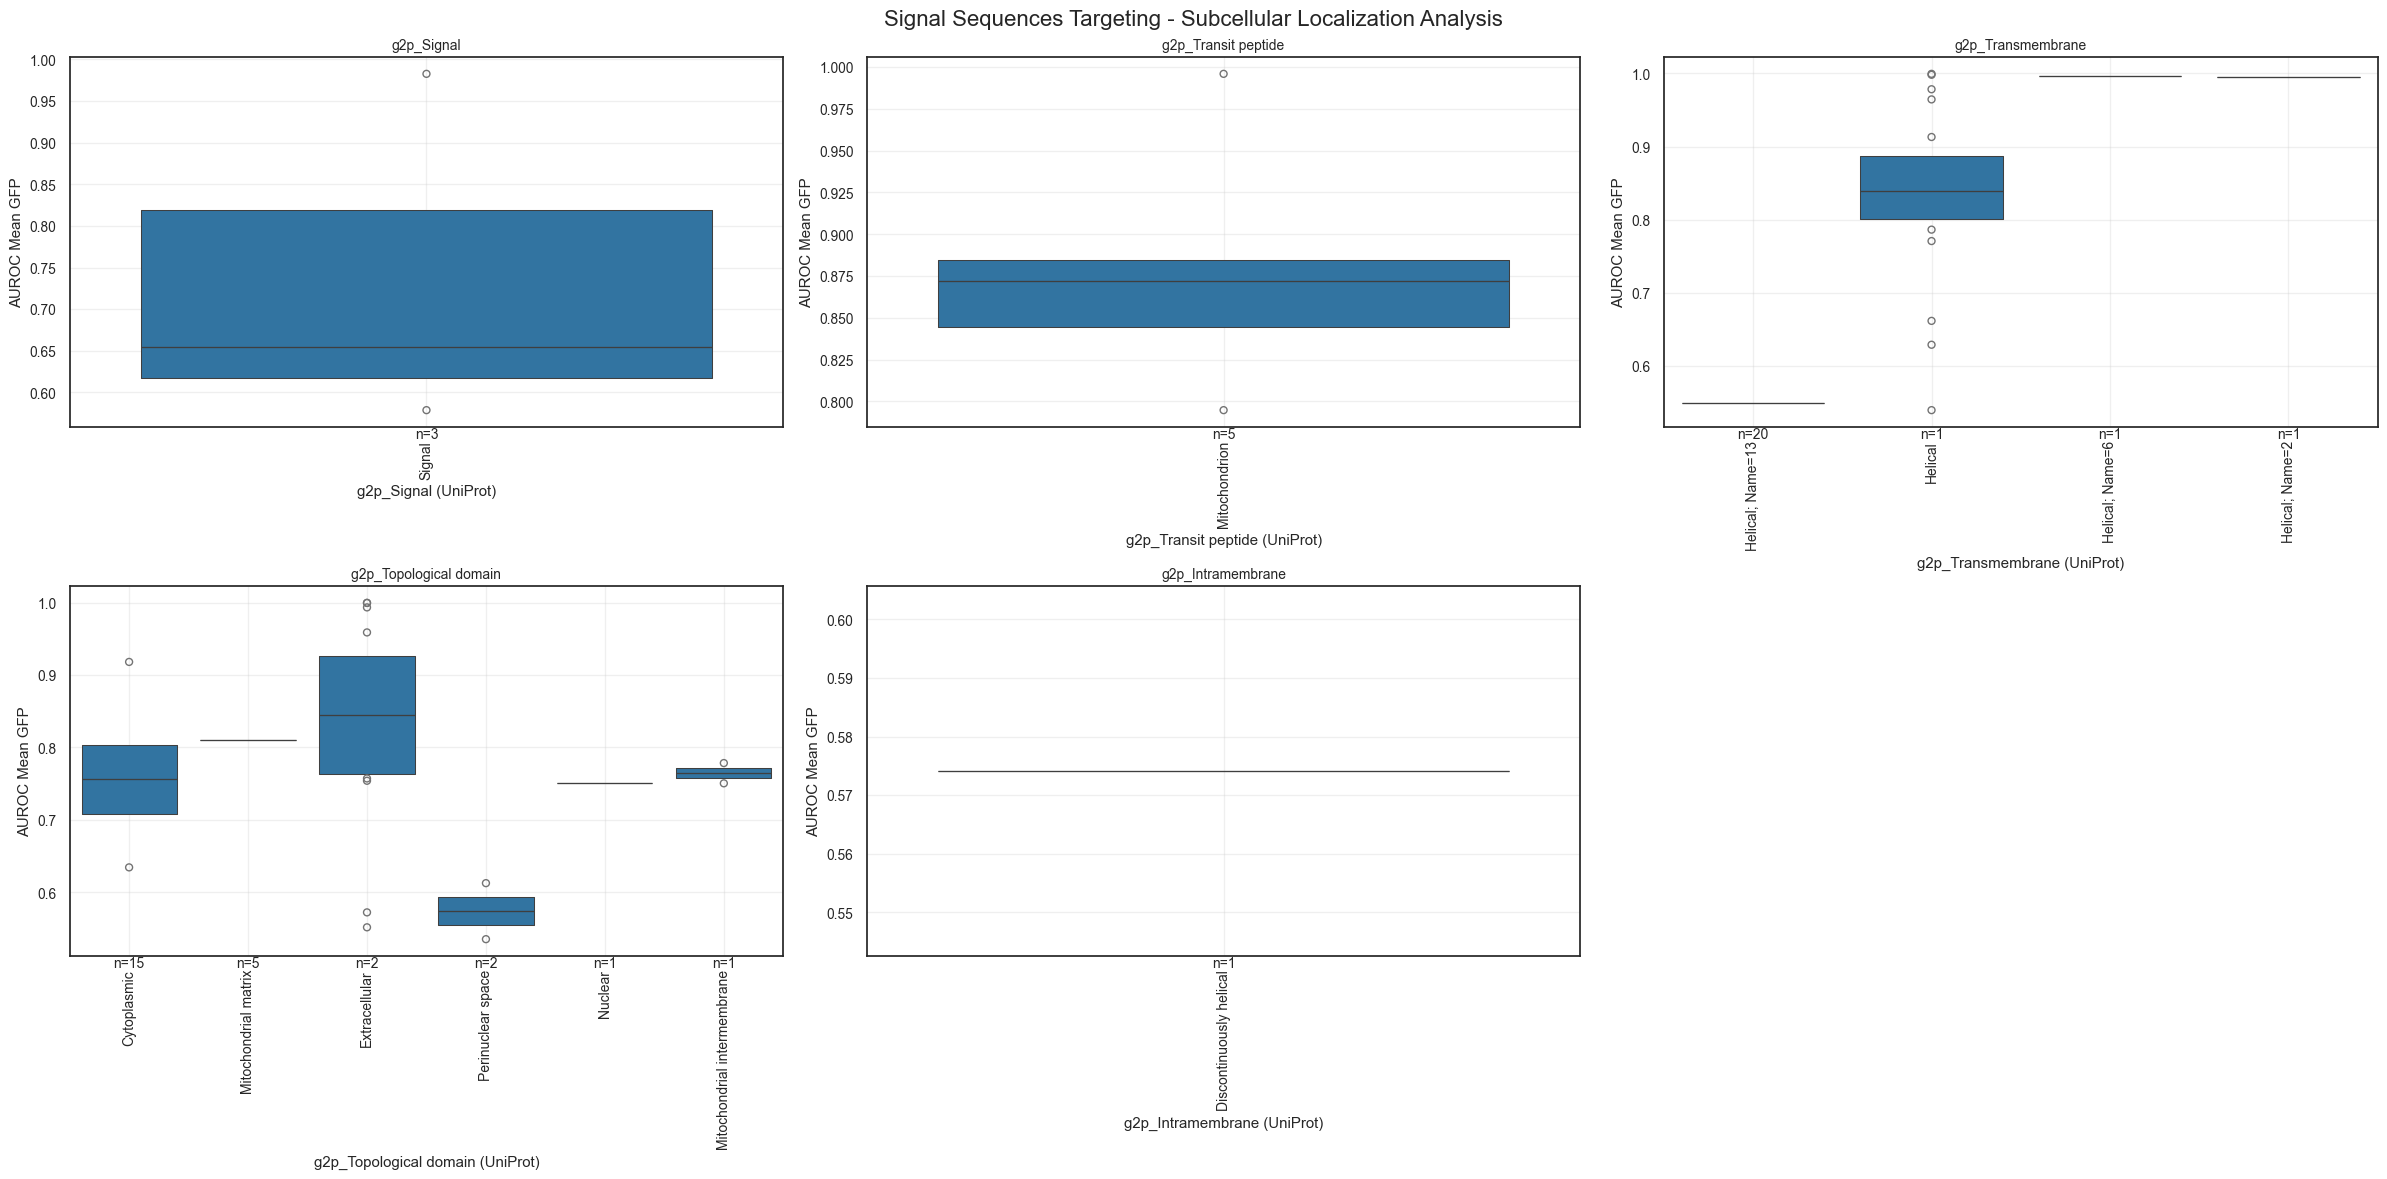


Signal Sequences Targeting Summary:
Features analyzed: 5
  g2p_Signal (UniProt): categorical, 3 non-null values
  g2p_Transit peptide (UniProt): categorical, 5 non-null values
  g2p_Transmembrane (UniProt): categorical, 23 non-null values
  g2p_Topological domain (UniProt): categorical, 26 non-null values
  g2p_Intramembrane (UniProt): categorical, 1 non-null values

ANALYZING: Nuclear Targeting


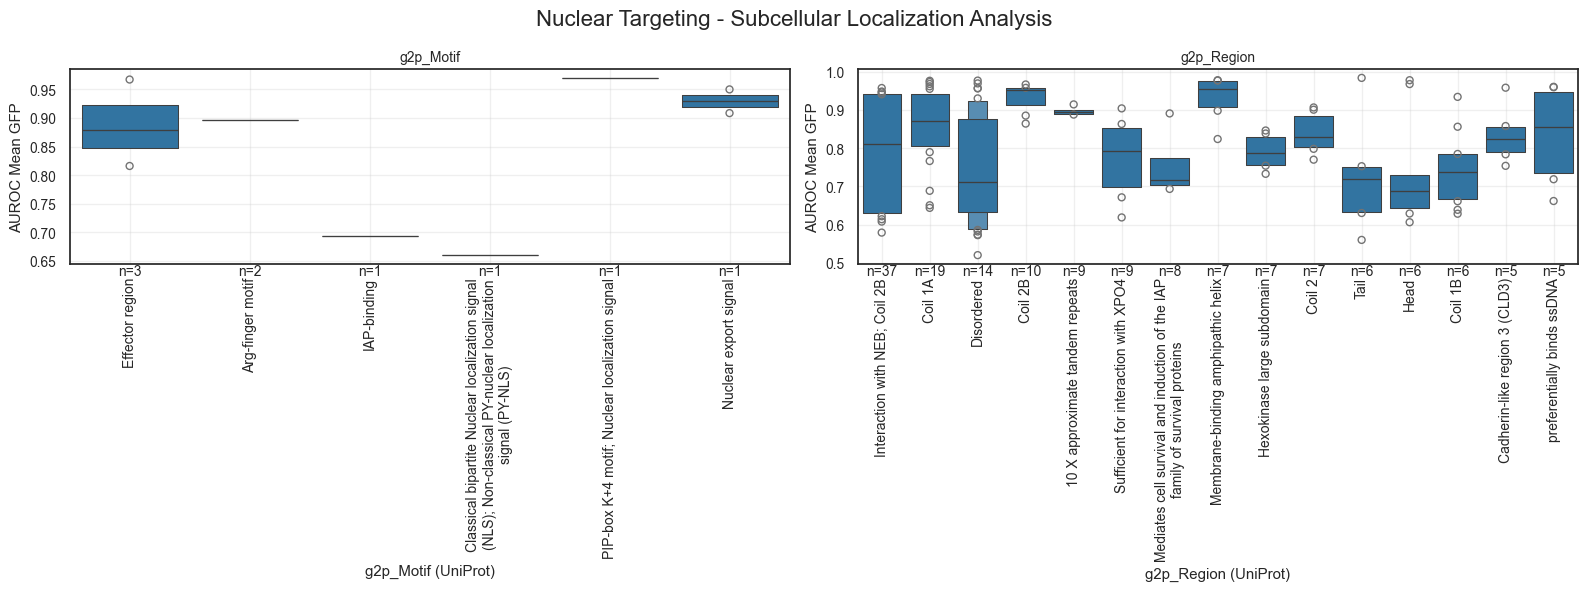


Nuclear Targeting Summary:
Features analyzed: 2
  g2p_Motif (UniProt): categorical, 9 non-null values
  g2p_Region (UniProt): categorical, 193 non-null values

ANALYZING: Structural Context


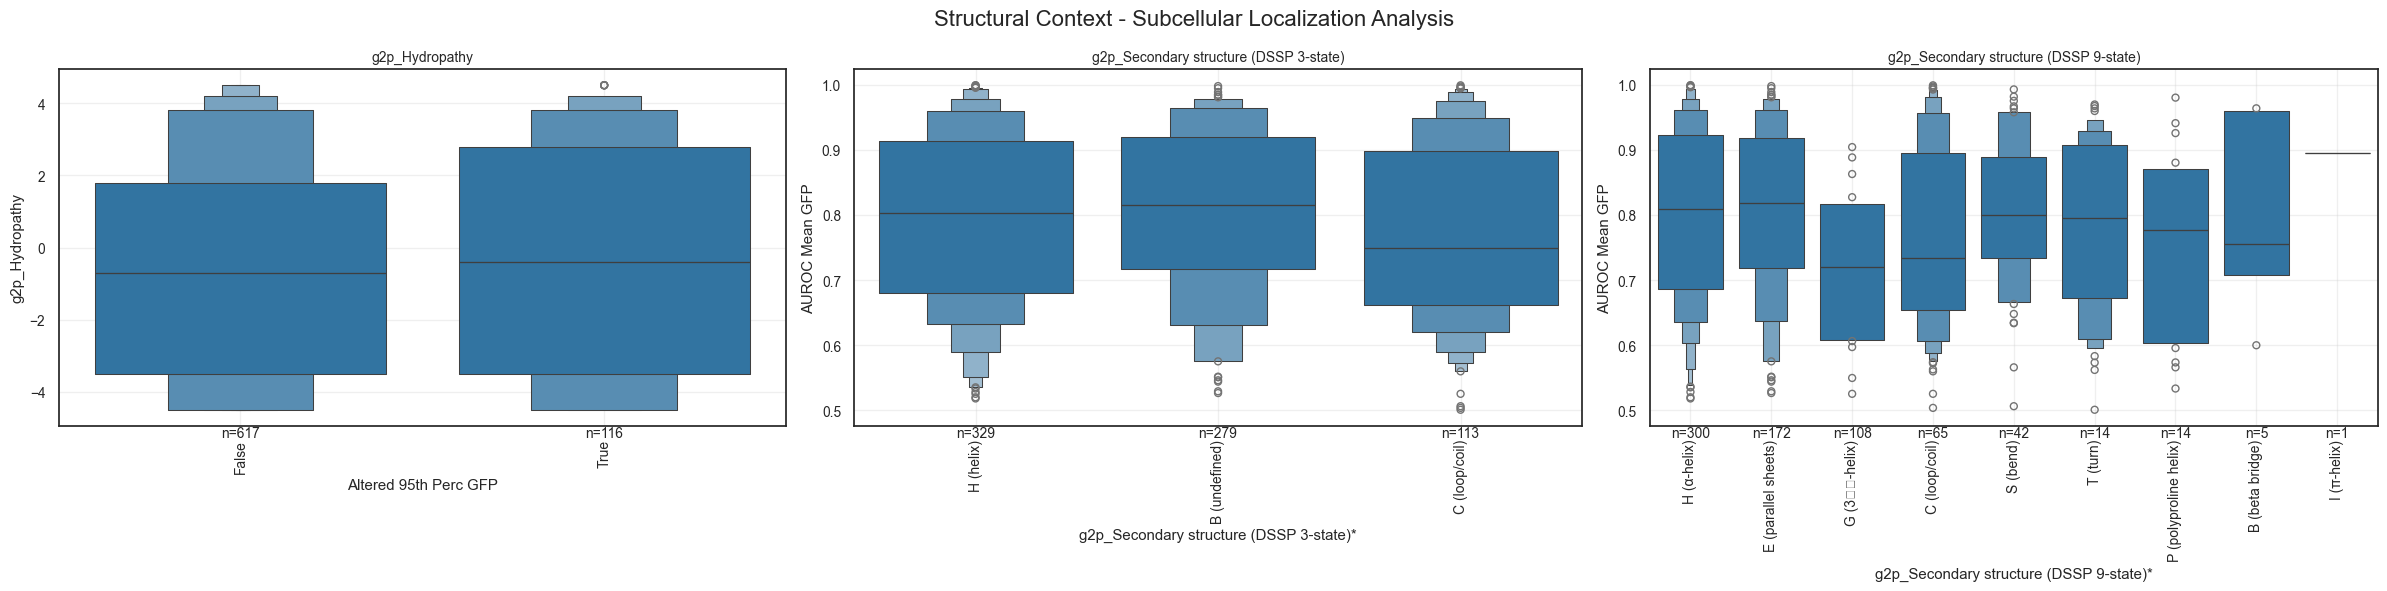


Structural Context Summary:
Features analyzed: 3
  g2p_Hydropathy: continuous, 733 non-null values
  g2p_Secondary structure (DSSP 3-state)*: categorical, 721 non-null values
  g2p_Secondary structure (DSSP 9-state)*: categorical, 721 non-null values

ANALYZING: Post Translational Modifications


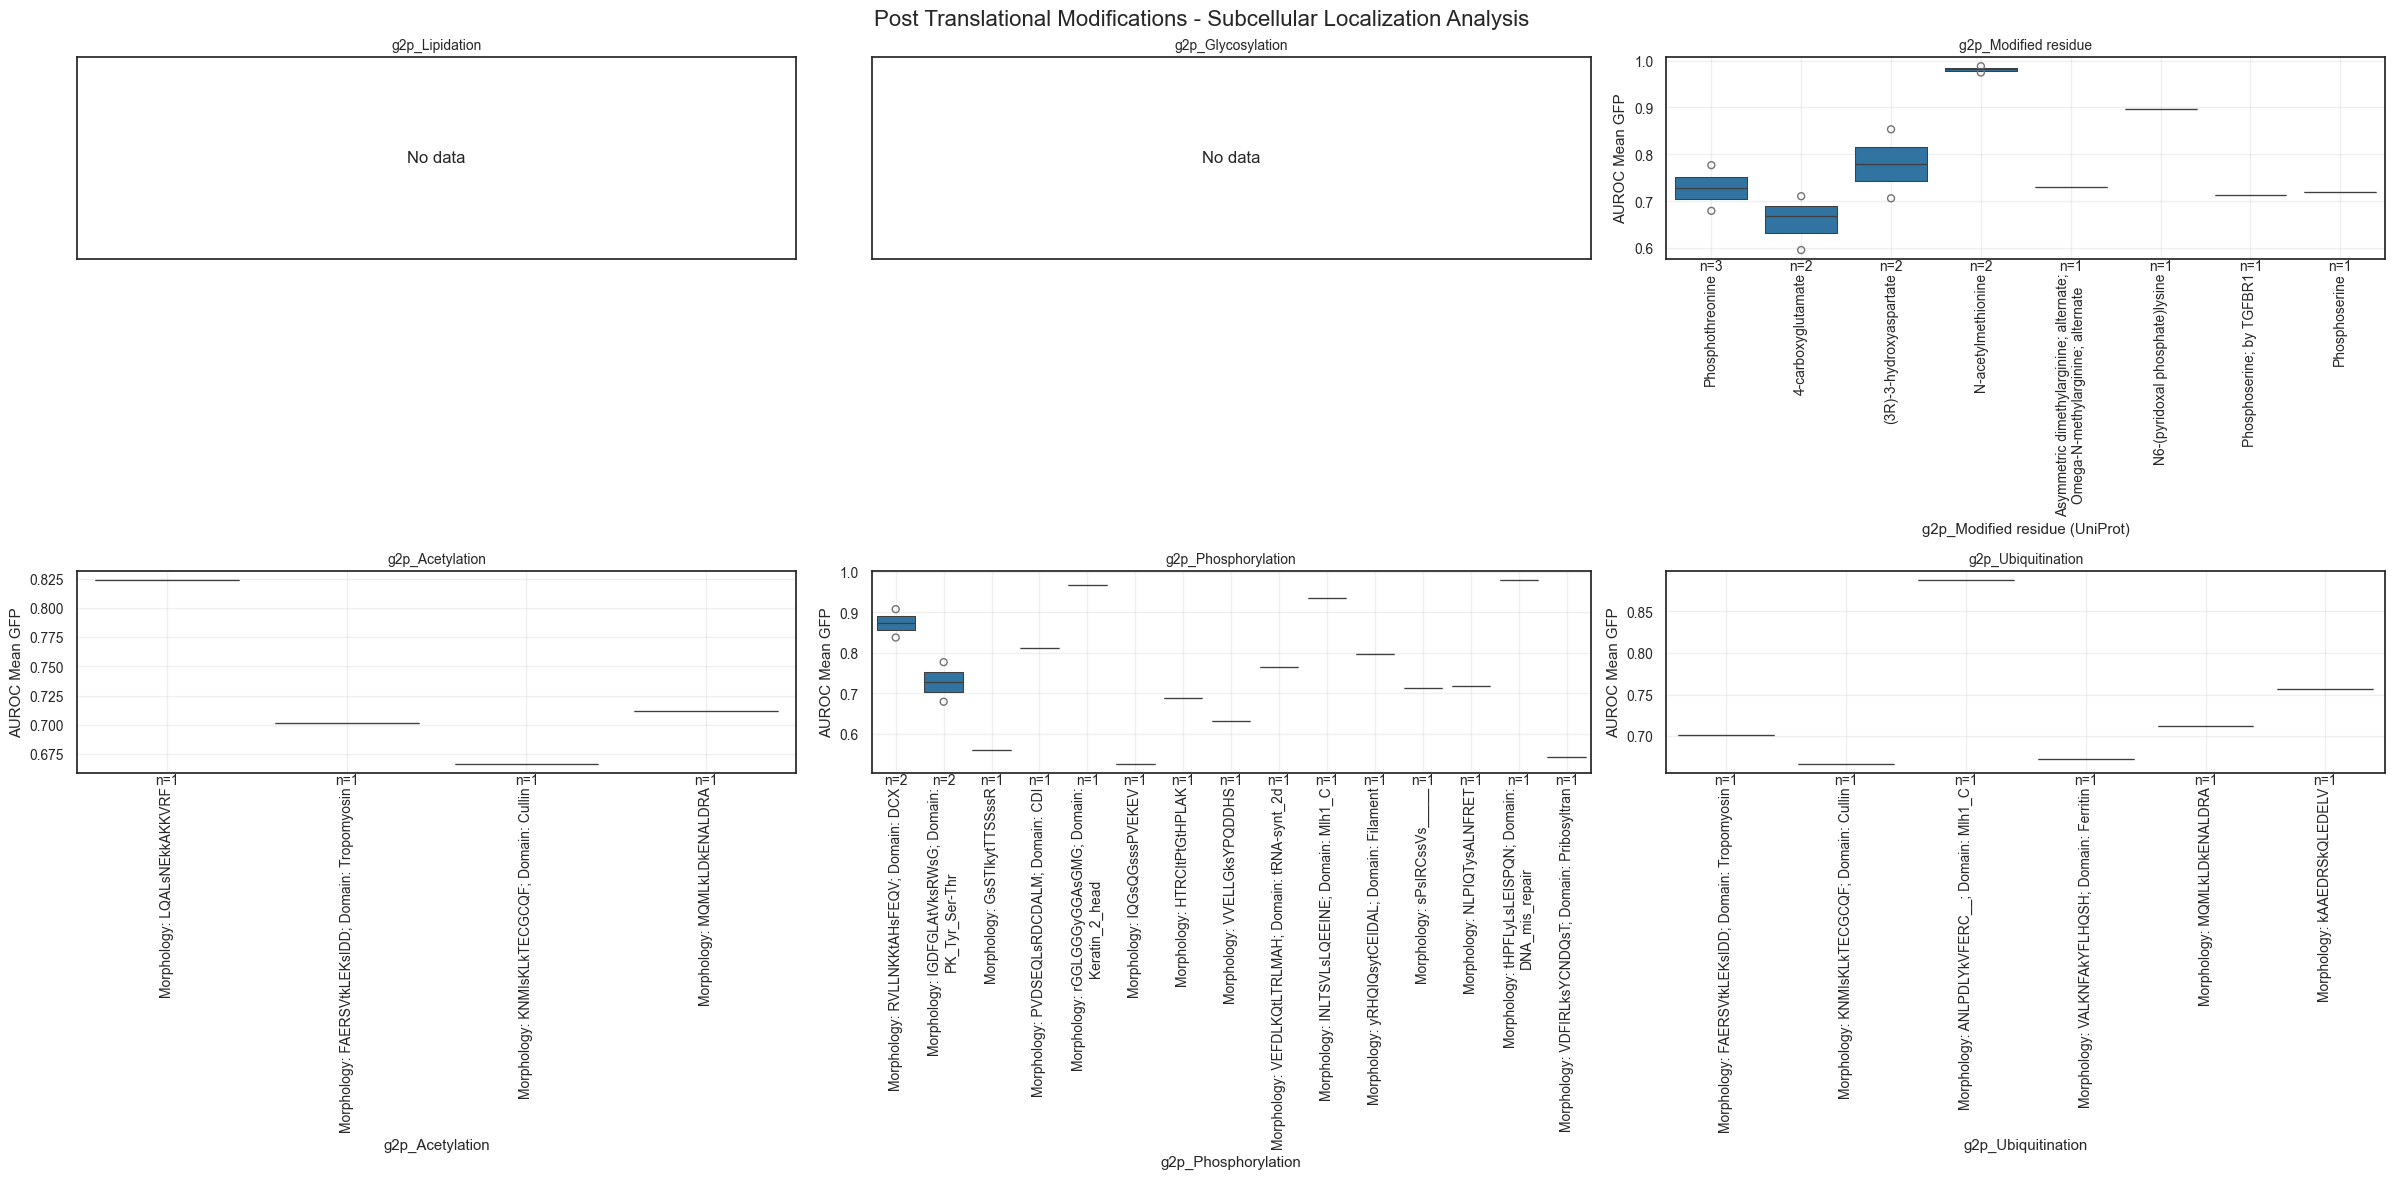


Post Translational Modifications Summary:
Features analyzed: 6
  g2p_Lipidation (UniProt): None, 0 non-null values
  g2p_Glycosylation (UniProt): None, 0 non-null values
  g2p_Modified residue (UniProt): categorical, 13 non-null values
  g2p_Acetylation: categorical, 4 non-null values
  g2p_Phosphorylation: categorical, 22 non-null values
  g2p_Ubiquitination: categorical, 6 non-null values

ANALYZING: Protein Domains Sites


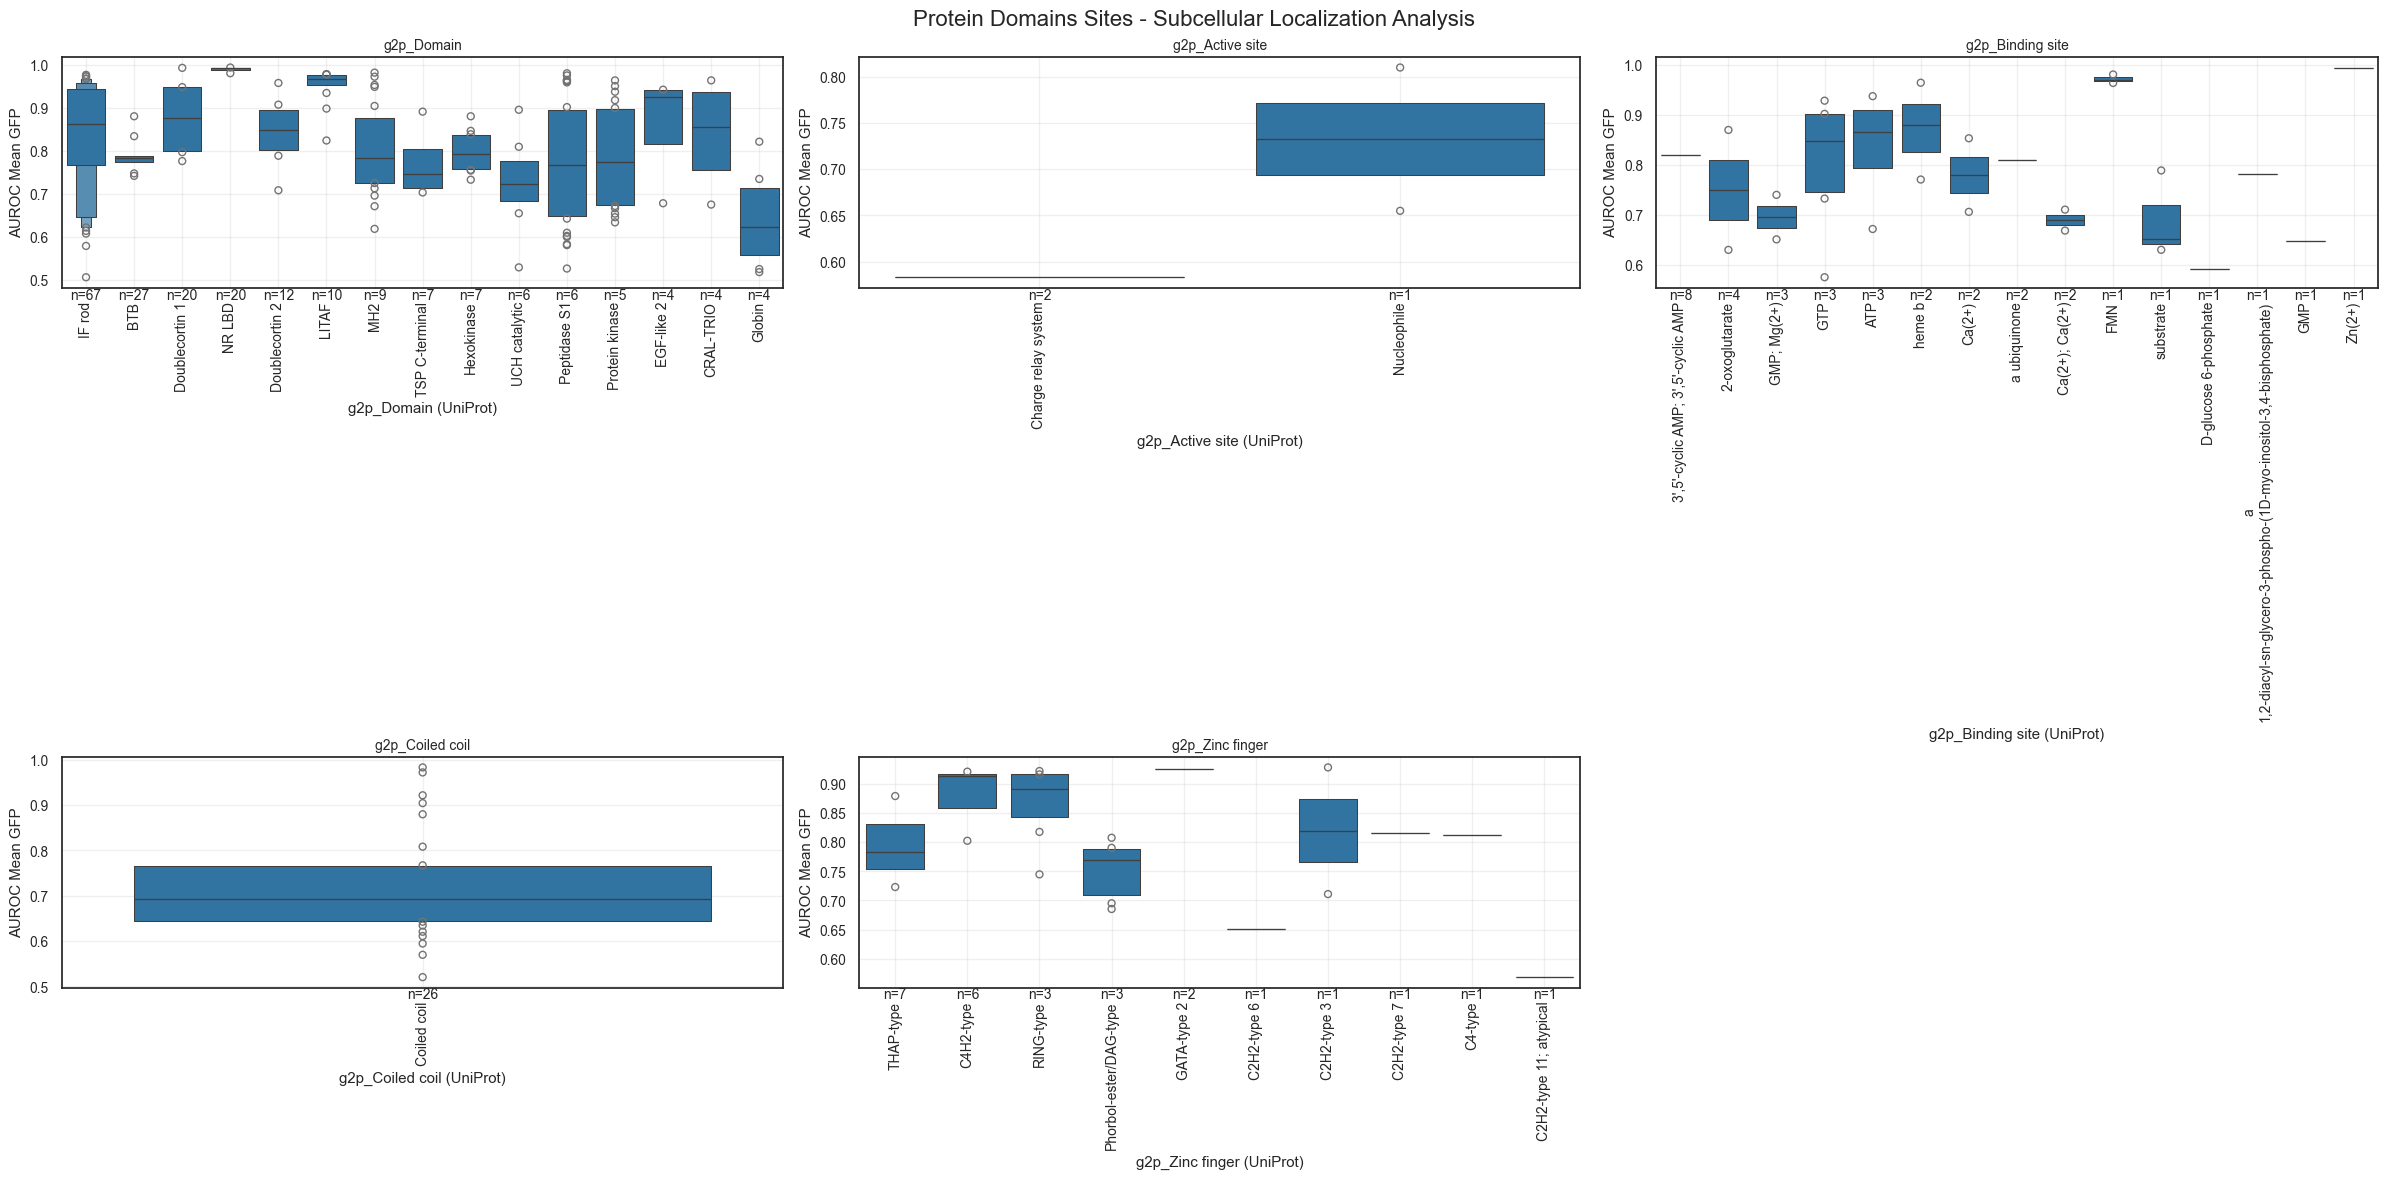


Protein Domains Sites Summary:
Features analyzed: 5
  g2p_Domain (UniProt): categorical, 256 non-null values
  g2p_Active site (UniProt): categorical, 3 non-null values
  g2p_Binding site (UniProt): categorical, 35 non-null values
  g2p_Coiled coil (UniProt): categorical, 26 non-null values
  g2p_Zinc finger (UniProt): categorical, 26 non-null values


In [56]:
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Read the data
df = imaging_summary_clinvar.to_pandas()

# Define feature categories for subcellular localization analysis
feature_categories = {
    'Signal_Sequences_Targeting': [
        'g2p_Signal (UniProt)',
        'g2p_Transit peptide (UniProt)', 
        'g2p_Transmembrane (UniProt)',
        'g2p_Topological domain (UniProt)',
        'g2p_Intramembrane (UniProt)'
    ],
    
    'Nuclear_Targeting': [
        'g2p_Motif (UniProt)',
        'g2p_Region (UniProt)'
    ],
    
    'Structural_Context': [
        'g2p_Hydropathy',
        'g2p_Secondary structure (DSSP 3-state)*',
        'g2p_Secondary structure (DSSP 9-state)*',
        # 'g2p_Accessible surface area (Å²)*',
        # 'g2p_AlphaFold confidence (pLDDT)'
    ],
    
    'Post_Translational_Modifications': [
        'g2p_Lipidation (UniProt)',
        'g2p_Glycosylation (UniProt)',
        'g2p_Modified residue (UniProt)',
        'g2p_Acetylation',
        'g2p_Phosphorylation',
        'g2p_Ubiquitination'
    ],
    
    'Protein_Domains_Sites': [
        'g2p_Domain (UniProt)',
        'g2p_Active site (UniProt)',
        'g2p_Binding site (UniProt)',
        'g2p_Coiled coil (UniProt)',
        'g2p_Zinc finger (UniProt)'
    ]
}

def determine_feature_type(df, feature):
    """Determine if feature is categorical or continuous"""
    if feature not in df.columns:
        return None
    
    # Get non-null values
    values = df[feature].dropna()
    if len(values) == 0:
        return None
    
    # Check if numeric
    if pd.api.types.is_numeric_dtype(values):
        return 'continuous'
    else:
        return 'categorical'

        
def clean_categorical_data(series, max_categories=15):
    """Clean categorical data for plotting"""
    # Remove null values
    cleaned = series.dropna()
    
    # Get value counts
    value_counts = cleaned.value_counts()
    
    # If too many categories, keep top N
    if len(value_counts) > max_categories:
        top_categories = value_counts.head(max_categories).index
        cleaned = cleaned[cleaned.isin(top_categories)]
    
    return cleaned


def format_long_string(text, max_chars=50):
    """Format long strings with line breaks at word boundaries"""
    if len(str(text)) <= max_chars:
        return str(text)
    
    words = str(text).split()
    lines = []
    current_line = ""
    
    for word in words:
        if len(current_line) == 0:
            current_line = word
        elif len(current_line) + len(word) + 1 <= max_chars:
            current_line += " " + word
        else:
            lines.append(current_line)
            current_line = word
    
    if current_line:
        lines.append(current_line)
    
    return "\n".join(lines)


def plot_category_analysis(df, category_name, features, figsize_per_plot=(8, 6)):
    """Plot analysis for a category of features"""
    # Filter valid features
    valid_features = [f for f in features if f in df.columns]
    if not valid_features:
        print(f"No valid features found for {category_name}")
        return
    
    # Calculate subplot layout
    n_features = len(valid_features)
    n_cols = min(3, n_features)
    n_rows = (n_features + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(figsize_per_plot[0] * n_cols, figsize_per_plot[1] * n_rows))
    if n_features == 1:
        axes = [axes]
    elif n_rows == 1:
        axes = [axes] if n_features == 1 else axes
    else:
        axes = axes.flatten()
    
    fig.suptitle(f'{category_name.replace("_", " ")} - Subcellular Localization Analysis', 
                 fontsize=16, fontweight='bold', y=0.98)
    
    for i, feature in enumerate(valid_features):
        ax = axes[i]
        
        # Determine feature type
        feature_type = determine_feature_type(df, feature)
        
        if feature_type is None:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=12)
            ax.set_title(feature.replace('protein_', '').replace(' (UniProt)', ''), fontsize=10)
            ax.set_xticks([])
            ax.set_yticks([])
            continue
        
        try:
            if feature_type == 'categorical':
                # For categorical features: boxenplot of AUROC_Mean_GFP per category
                plot_data = df[[feature, 'AUROC_Mean_GFP']].dropna()
                if len(plot_data) == 0:
                    ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=12)
                    ax.set_xticks([])
                    ax.set_yticks([])
                else:
                    # Clean categorical data
                    cleaned_feature = clean_categorical_data(plot_data[feature])
                    plot_data_clean = plot_data[plot_data[feature].isin(cleaned_feature)]
                    if len(plot_data_clean) == 0:
                        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=12)
                        ax.set_xticks([])
                        ax.set_yticks([])
                    else:
                        # Format long category labels
                        plot_data_clean = plot_data_clean.copy()
                        plot_data_clean[feature] = plot_data_clean[feature].apply(format_long_string)
                        
                        sns.boxenplot(data=plot_data_clean, x=feature, y='AUROC_Mean_GFP', ax=ax)
                        ax.tick_params(axis='x', rotation=90, labelsize=10)
                        ax.set_ylabel('AUROC Mean GFP')
                        
                        # Add sample sizes
                        cat_counts = plot_data_clean[feature].value_counts()
                        for j, (cat, count) in enumerate(cat_counts.items()):
                            ax.text(j, ax.get_ylim()[0]-1e-4, f'n={count}', ha='center', va='top', fontsize=10)
            
            else:  # continuous
                # For continuous features: boxenplot per Altered_95th_perc_both_batches_GFP category
                plot_data = df[[feature, 'Altered_95th_perc_both_batches_GFP']].dropna()
                
                if len(plot_data) == 0:
                    ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=10)
                    ax.set_xticks([])
                    ax.set_yticks([])
                else:
                    # Format long category labels
                    plot_data = plot_data.copy()
                    plot_data['Altered_95th_perc_both_batches_GFP'] = plot_data['Altered_95th_perc_both_batches_GFP'].apply(format_long_string)
                    
                    sns.boxenplot(data=plot_data, x='Altered_95th_perc_both_batches_GFP', y=feature, ax=ax)
                    ax.set_xlabel('Altered 95th Perc GFP')
                    ax.tick_params(axis='x', rotation=90, labelsize=10)
                    
                    # Add sample sizes
                    cat_counts = plot_data['Altered_95th_perc_both_batches_GFP'].value_counts()
                    for j, (cat, count) in enumerate(cat_counts.items()):
                        ax.text(j, ax.get_ylim()[0]-1e-4, f'n={count}', ha='center', va='top', fontsize=10)
    
        except Exception as e:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=10)
            ax.set_xticks([])
            ax.set_yticks([])
            print(f"Error plotting {feature}: {e}")
        
        # Clean up title
        clean_title = feature.replace('protein_', '').replace(' (UniProt)', '').replace('*', '')
        ax.set_title(clean_title, fontsize=10, fontweight='bold')
        ax.grid(True, alpha=0.3)
    
    # Hide empty subplots
    for i in range(len(valid_features), len(axes)):
        axes[i].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print(f"\n{category_name.replace('_', ' ')} Summary:")
    print(f"Features analyzed: {len(valid_features)}")
    
    for feature in valid_features:
        feature_type = determine_feature_type(df, feature)
        non_null_count = df[feature].notna().sum()
        print(f"  {feature}: {feature_type}, {non_null_count} non-null values")

# Print the feature categories dictionary
print("Feature Categories for Subcellular Localization Analysis:")
print("=" * 60)
for category, features in feature_categories.items():
    print(f"\n{category.replace('_', ' ')}:")
    for feature in features:
        print(f"  - {feature}")

print(f"\nDataset shape: {df.shape}")
print(f"AUROC_Mean_GFP range: {df['AUROC_Mean_GFP'].min():.3f} - {df['AUROC_Mean_GFP'].max():.3f}")
print(f"Altered_95th_perc_both_batches_GFP categories: {df['Altered_95th_perc_both_batches_GFP'].value_counts()}")

# Run analysis for each category
for category_name, features in feature_categories.items():
    print(f"\n{'='*80}")
    print(f"ANALYZING: {category_name.replace('_', ' ')}")
    print(f"{'='*80}")
    plot_category_analysis(df, category_name, features)